# Variational autoencoder on MNIST and Fashion-MNIST

In this notebook, I train a convolutional VAE on MNIST and Fashion-MNIST using two latent dimensions: 2 and 20. I want to compare how the size of the latent space affects reconstruction and image generation.

I use the same architecture and training parameters for both datasets, changing only the latent dimension. I also look at the learned representations and generate new images by sampling from the latent space.

## 1. Setup


In [12]:
from pathlib import Path
import sys
import json
import hashlib
import gc
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import ToTensor
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "src/models.py").is_file() and (p / "data/splits").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Put this notebook in notebooks/ and the supplied Python files in src/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models import ConvVAE
from src.training import set_seed, vae_loss, fit_vae, load_vae

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 111
set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Training settings

The first pass uses 2,048 training images, 512 validation images, and two epochs per configuration. This checks the full workflow; it is too short to assess model quality. Set `SMOKE_TEST=False` for the full splits and 30 epochs.

Each run saves its configuration, weights, loss history, and timing. Smoke runs and full runs have separate names. Completed matching runs can be loaded again without retraining. To start a new experiment, change `RUN_TAG`; interrupted runs are not automatically resumed.


In [13]:
SMOKE_TEST = False
REUSE_COMPLETED = True
RUN_TAG = "baseline_v1"
DATASET_NAMES = ["mnist", "fashion_mnist"]
LATENT_DIMS = [2, 20]
BATCH_SIZE = 64
HIDDEN_DIM = 128
LEARNING_RATE = 1e-3
BETA = 1.0
EPOCHS = 2 if SMOKE_TEST else 30
NUM_WORKERS = 0
SAVE_FIGURES = True

MODE = "smoke" if SMOKE_TEST else "full"
FIG_DIR = ROOT / "results/figures/vae" / f"{RUN_TAG}_{MODE}"
FIG_DIR.mkdir(parents=True, exist_ok=True)
# Changing shared model/training code invalidates reuse of an old run.
CODE_HASH = hashlib.sha256(b"".join((ROOT / p).read_bytes()
    for p in ["src/models.py", "src/training.py"])).hexdigest()

def show_figure(fig, filename):
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"Mode: {MODE}; epochs per run: {EPOCHS}; configurations: {len(DATASET_NAMES) * len(LATENT_DIMS)}")


Mode: full; epochs per run: 30; configurations: 4


## 3. Load the saved splits

Pixels are mapped to $[0,1]$ with `ToTensor()`. We reuse the saved training and validation indices from the previous notebook. The official test set stays untouched during this stage.

The smoke run takes reproducible random subsets of these splits. Both latent dimensions see the same subset and initial shuffle seed. No label is passed to the model.


In [14]:
data = {}
for name in DATASET_NAMES:
    dataset_class = {"mnist": MNIST, "fashion_mnist": FashionMNIST}[name]
    dataset = dataset_class(ROOT / "data/raw", train=True, download=False, transform=ToTensor())
    split_path = ROOT / "data/splits" / f"{name}_seed{SEED}.npz"
    with np.load(split_path, allow_pickle=False) as saved:
        train_idx, val_idx = saved["train_idx"].copy(), saved["val_idx"].copy()
    assert len(train_idx) == 50000 and len(val_idx) == 10000
    assert np.array_equal(np.sort(np.concatenate([train_idx, val_idx])), np.arange(len(dataset)))
    if SMOKE_TEST:
        rng = np.random.default_rng(SEED)
        train_idx = rng.choice(train_idx, 2048, replace=False)
        val_idx = rng.choice(val_idx, 512, replace=False)
    data[name] = {"dataset": dataset, "train_idx": train_idx, "val_idx": val_idx,
                  "split_sha256": hashlib.sha256(split_path.read_bytes()).hexdigest(),
                  "classes": [str(i) for i in range(10)] if name == "mnist" else dataset.classes}
    print(f"{name}: {len(train_idx):,} train / {len(val_idx):,} validation")

def make_loaders(name):
    entry = data[name]
    train_loader = DataLoader(Subset(entry["dataset"], entry["train_idx"].tolist()),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED), pin_memory=device.type == "cuda")
    val_loader = DataLoader(Subset(entry["dataset"], entry["val_idx"].tolist()),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED + 1), pin_memory=device.type == "cuda")
    return train_loader, val_loader


mnist: 50,000 train / 10,000 validation
fashion_mnist: 50,000 train / 10,000 validation


## 4. Encoder, sampling, and decoder

The encoder applies two convolutional layers and max pooling, reducing the image from $28\times28$ to $7\times7$. A fully connected layer produces features for two separate heads: $\mu$ and $\log\sigma^2$.

The latent vector is sampled as

$$z = \mu + \exp(0.5\log\sigma^2)\odot\epsilon,
\qquad \epsilon\sim\mathcal{N}(0,I).$$

Writing the random sample this way allows gradients to pass through $\mu$ and $\log\sigma^2$. The log-variance itself is not the standard deviation.

The decoder expands $z$ into feature maps and uses transposed convolutions to recover the original image size. Unlike the original max-unpool decoder, it needs no information from an input image, so it can decode a sample drawn directly from the prior.

| Stage | Output shape, excluding batch |
| --- | --- |
| Input | 1 × 28 × 28 |
| Convolution + pooling | 32 × 14 × 14 |
| Convolution + pooling | 64 × 7 × 7 |
| Fully connected | 128 |
| Mean and log-variance heads | d each |
| Sampled latent vector | d |
| Decoder fully connected layers | 64 × 7 × 7 |
| Transposed convolution | 32 × 14 × 14 |
| Transposed convolution | 1 × 28 × 28 |

Here $d$ is 2 or 20. The hidden width is fixed at 128 rather than using the different widths in the original experiments. This keeps the comparison focused on latent dimension.


In [15]:
set_seed(SEED)
model = ConvVAE(latent_dim=2, hidden_dim=HIDDEN_DIM).to(device)
example_loader, _ = make_loaders(DATASET_NAMES[0])
x, _ = next(iter(example_loader))
x = x[:4].to(device)
with torch.no_grad():
    logits, mu, logvar = model(x)
    generated = model.decode(torch.randn(4, 2, device=device))
assert logits.shape == generated.shape == x.shape
assert mu.shape == logvar.shape == (4, 2)
print(model)
print("Input/output:", tuple(x.shape), "Latent:", tuple(mu.shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))
del model, x, logits, mu, logvar, generated, example_loader


ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): LeakyReLU(negative_slope=0.2)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=3136, out_features=128, bias=True)
    (8): LeakyReLU(negative_slope=0.2)
  )
  (mean_layer): Linear(in_features=128, out_features=2, bias=True)
  (logvar_layer): Linear(in_features=128, out_features=2, bias=True)
  (decoder_input): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=3136, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(6

## 5. Loss function

The objective combines reconstruction error with a penalty that keeps the approximate posterior close to a standard normal prior:

$$\mathcal L = \mathrm{BCE}(x,\hat x)
+ \beta\,D_{KL}\left(q(z\mid x)\,\|\,\mathcal N(0,I)\right),$$

$$D_{KL} = -\frac{1}{2}\sum_j
\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

We sum reconstruction loss over pixels and KL over latent coordinates, then average over images. This avoids changing the reported scale when the last batch is smaller. The baseline uses $\beta=1$.

The model returns logits during training. `binary_cross_entropy_with_logits` applies the sigmoid internally in a numerically stable form. For plotting, `model.decode()` returns values in $[0,1]$. BCE on grayscale targets is a baseline modeling choice; the images are not binarized.


In [16]:
# At mu=0 and logvar=0, the posterior equals the standard normal prior.
zeros = torch.zeros(4, 2)
total, reconstruction, kl = vae_loss(torch.zeros(4, 1, 28, 28),
                                   torch.zeros(4, 1, 28, 28), zeros, zeros, beta=BETA)
assert torch.isclose(kl, torch.tensor(0.0))
print(f"Sanity check: KL = {kl.item():.1f}")


Sanity check: KL = -0.0


## 6. Train the four configurations

Adam updates the model using the training split. Validation uses one posterior sample per image and a fixed noise stream across epochs. We select the checkpoint with the lowest validation objective.

The loss is therefore a sampled estimate, not an exact likelihood. Training and validation losses can also differ because training loss is accumulated while the weights are changing.

Timing includes the training and validation passes, but excludes checkpoint writing. Reproducible seeds help comparisons on the same setup; they do not guarantee identical results across different hardware or package versions.


In [17]:
runs = {}
for name in DATASET_NAMES:
    for latent_dim in LATENT_DIMS:
        run_id = f"{RUN_TAG}_{name}_z{latent_dim}_{MODE}_seed{SEED}"
        checkpoint_dir = ROOT / "checkpoints/vae" / run_id
        metric_dir = ROOT / "results/metrics/vae" / run_id
        config = {"run_id": run_id, "dataset": name, "latent_dim": latent_dim,
                  "hidden_dim": HIDDEN_DIM, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
                  "learning_rate": LEARNING_RATE, "beta": BETA, "seed": SEED,
                  "smoke_test": SMOKE_TEST, "train_size": len(data[name]["train_idx"]),
                  "val_size": len(data[name]["val_idx"]), "num_workers": NUM_WORKERS,
                  "split_sha256": data[name]["split_sha256"], "code_sha256": CODE_HASH,
                  "python_version": platform.python_version(), "torch_version": str(torch.__version__),
                  "device": str(device),
                  "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else platform.processor()}
        completed = (metric_dir / "summary.json").exists()
        if REUSE_COMPLETED and completed:
            previous = json.loads((metric_dir / "config.json").read_text())
            if previous != config:
                raise ValueError(f"Settings changed for {run_id}. Choose a new RUN_TAG.")
            if not (checkpoint_dir / "best.pt").exists():
                raise FileNotFoundError(f"Missing weights for {run_id}. Restore them or choose a new RUN_TAG.")
            history = pd.read_csv(metric_dir / "history.csv")
            summary = json.loads((metric_dir / "summary.json").read_text())
            print("Loaded completed run:", run_id)
        else:
            set_seed(SEED)
            train_loader, val_loader = make_loaders(name)
            model = ConvVAE(latent_dim, HIDDEN_DIM).to(device)
            history, summary = fit_vae(model, train_loader, val_loader, device,
                                      config, checkpoint_dir, metric_dir)
            del model, train_loader, val_loader
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
        runs[(name, latent_dim)] = {"checkpoint": checkpoint_dir / "best.pt",
                                    "history": history, "summary": summary, "config": config}

run_summary = pd.DataFrame([{"dataset": name, "latent_dim": dim, "mode": MODE,
                             **run["summary"]} for (name, dim), run in runs.items()])
display(run_summary)
run_summary.to_csv(ROOT / "results/metrics" / f"vae_{RUN_TAG}_{MODE}_summary.csv", index=False)


baseline_v1_mnist_z2_full_seed111:   3%|▎         | 1/30 [00:08<04:03,  8.40s/it]

Epoch 01: train=174.43, val=160.86, recon=155.67, KL=5.19 (8.4s)


baseline_v1_mnist_z2_full_seed111:   7%|▋         | 2/30 [00:16<03:46,  8.09s/it]

Epoch 02: train=158.02, val=156.25, recon=150.78, KL=5.47 (7.8s)


baseline_v1_mnist_z2_full_seed111:  10%|█         | 3/30 [00:24<03:34,  7.96s/it]

...

baseline_v1_fashion_mnist_z20_full_seed111:  97%|█████████▋| 29/30 [04:01<00:08,  8.17s/it]

Epoch 29: train=235.60, val=235.84, recon=221.16, KL=14.69 (8.1s)


baseline_v1_fashion_mnist_z20_full_seed111: 100%|██████████| 30/30 [04:10<00:00,  8.33s/it]

Epoch 30: train=235.53, val=235.60, recon=220.90, KL=14.69 (8.1s)


,dataset,latent_dim,mode,best_epoch,best_val_loss,train_and_validation_seconds,parameter_count,peak_allocated_MiB
0,mnist,2,full,30,144.493238,244.989279,859109,65.561523
1,mnist,20,full,29,97.068160,248.998485,866057,65.671387
2,fashion_mnist,2,full,28,257.447569,249.467960,859109,65.561523
3,fashion_mnist,20,full,30,235.596565,248.575628,866057,65.671387


## 7. Training curves

Plotting reconstruction and KL separately shows whether improvements in the total objective come from better reconstructions or stronger regularization. A small KL term alone does not demonstrate a useful representation; the decoder may be ignoring some latent coordinates.


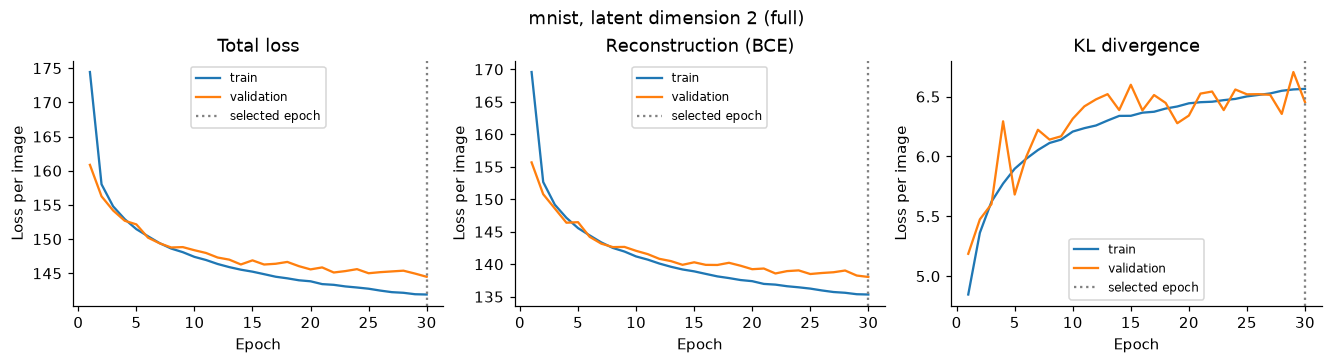

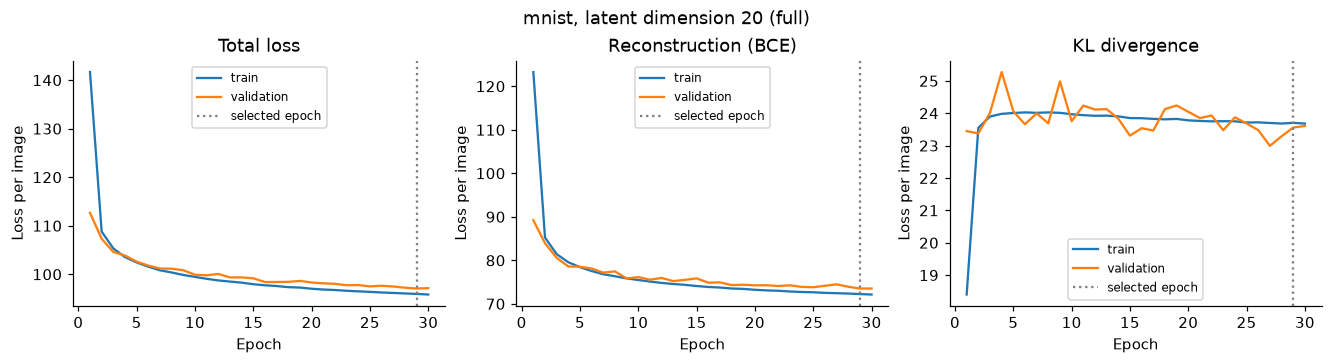

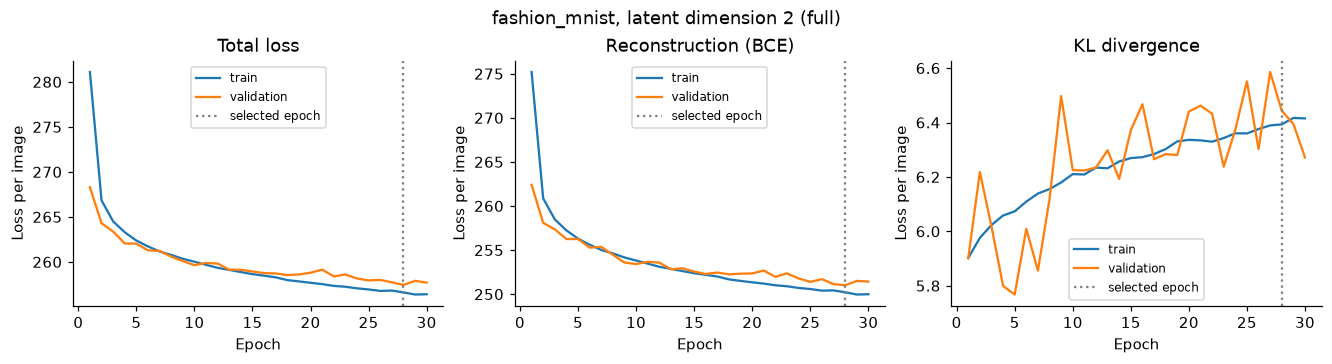

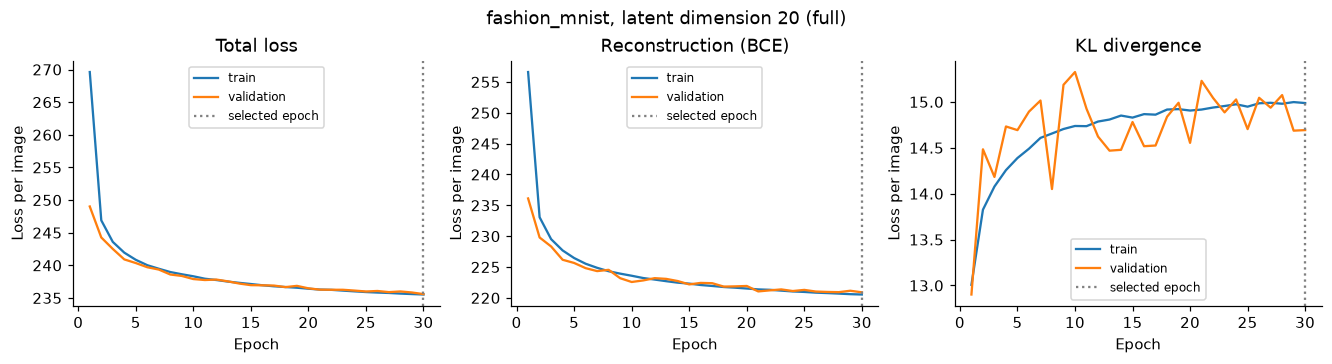

In [18]:
for (name, dim), run in runs.items():
    h = run["history"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), constrained_layout=True)
    for ax, metric, title in zip(axes, ["loss", "reconstruction", "kl"],
                                 ["Total loss", "Reconstruction (BCE)", "KL divergence"]):
        ax.plot(h["epoch"], h[f"train_{metric}"], label="train")
        ax.plot(h["epoch"], h[f"val_{metric}"], label="validation")
        ax.axvline(run["summary"]["best_epoch"], color="gray", linestyle=":", label="selected epoch")
        ax.set(xlabel="Epoch", ylabel="Loss per image", title=title)
        ax.legend(fontsize=8)
    fig.suptitle(f"{name}, latent dimension {dim} ({MODE})")
    show_figure(fig, f"{name}_z{dim}_loss.png")


## 8. Reconstructions

To compare the reconstructions, I selected one image from each class in the validation set. I use the same images for both models to see how the latent dimension affects the output.
Instead of sampling a random latent vector, I use the mean predicted by the encoder. This makes the comparison easier because the reconstructions do not change between runs.


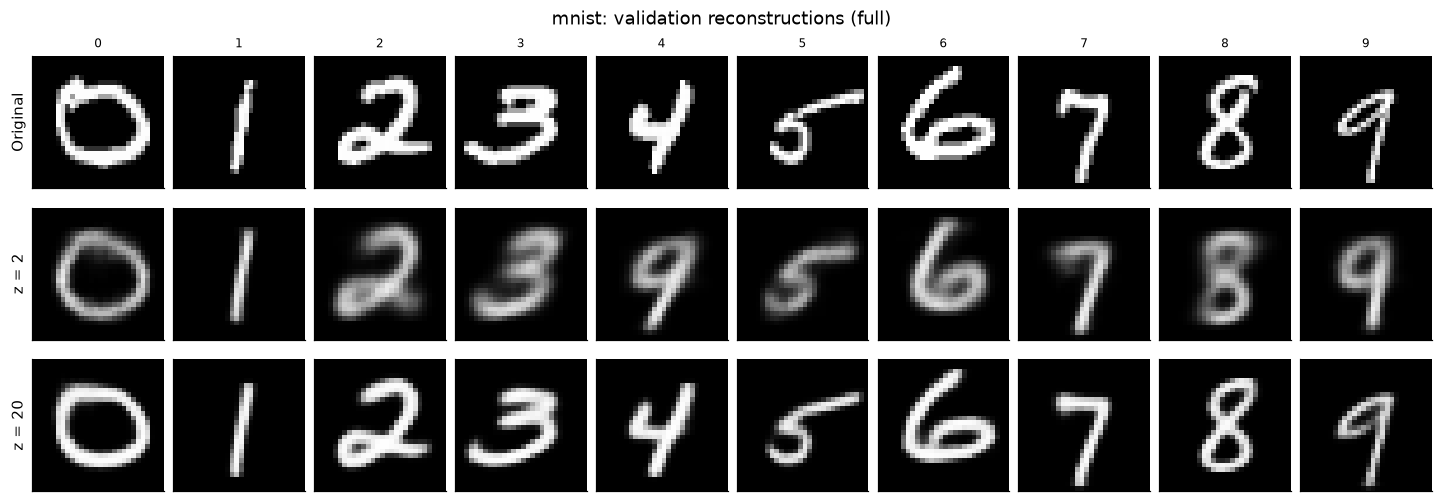

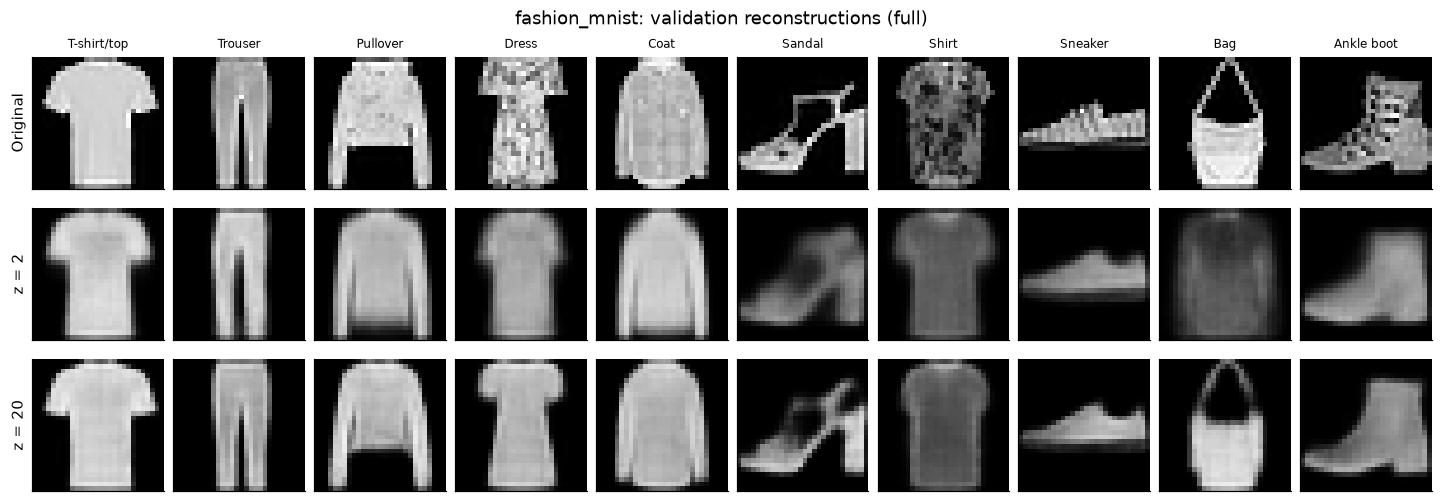

In [19]:
examples = {}
for name in DATASET_NAMES:
    entry = data[name]
    targets = entry["dataset"].targets.numpy()
    selected = [next(int(i) for i in entry["val_idx"] if targets[i] == label) for label in range(10)]
    examples[name] = torch.stack([entry["dataset"][i][0] for i in selected])
    fig, axes = plt.subplots(1 + len(LATENT_DIMS), 10, figsize=(13, 4.5), squeeze=False,
                             constrained_layout=True)
    rows = [examples[name]]
    for dim in LATENT_DIMS:
        model, _ = load_vae(runs[(name, dim)]["checkpoint"], device)
        with torch.inference_mode():
            mu, _ = model.encode(examples[name].to(device))
            rows.append(model.decode(mu).cpu())
        del model
    for row, images in enumerate(rows):
        for label in range(10):
            axes[row, label].imshow(images[label, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            axes[row, label].set_xticks([])
            axes[row, label].set_yticks([])
            if row == 0:
                axes[row, label].set_title(entry["classes"][label], fontsize=8)
        axes[row, 0].set_ylabel("Original" if row == 0 else f"z = {LATENT_DIMS[row - 1]}")
    fig.suptitle(f"{name}: validation reconstructions ({MODE})")
    show_figure(fig, f"{name}_reconstructions.png")


## 9. Generate images from the prior

We draw 64 vectors from a standard normal distribution and decode them without providing an input image or class label. The grid shows all samples from a fixed seed, rather than a selection of the best-looking ones.

The displayed pixels are decoder probabilities (continuous grayscale values); we do not draw binary pixels from the Bernoulli output distribution.


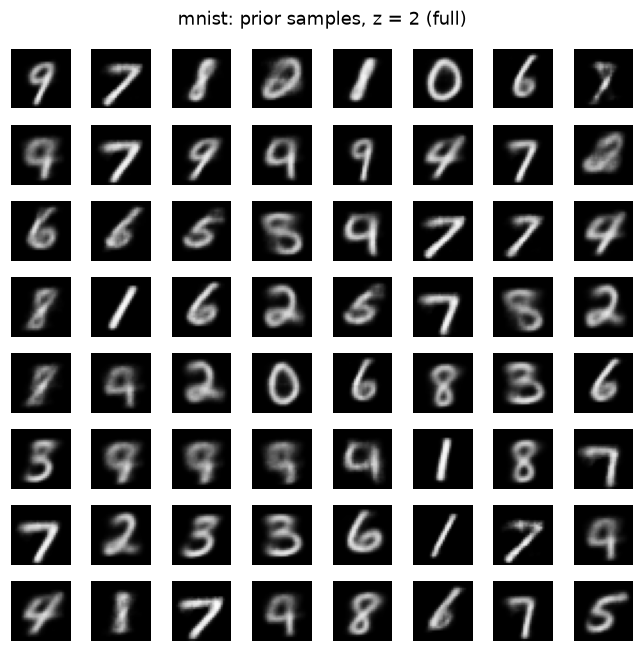

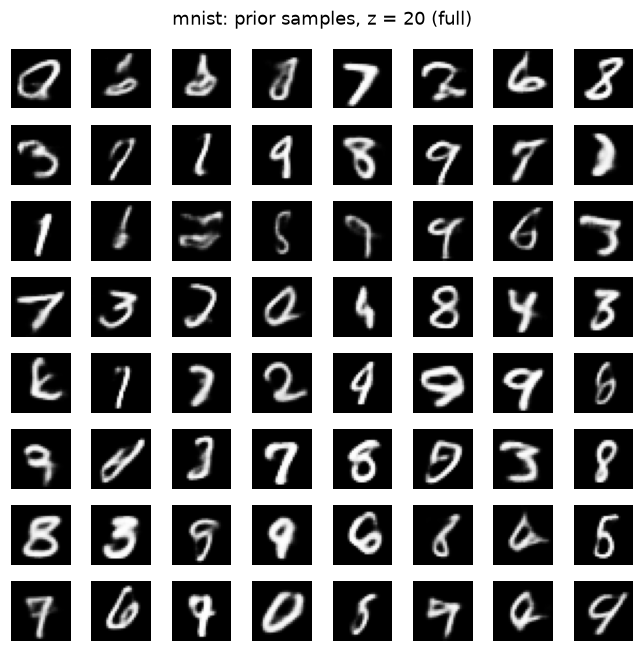

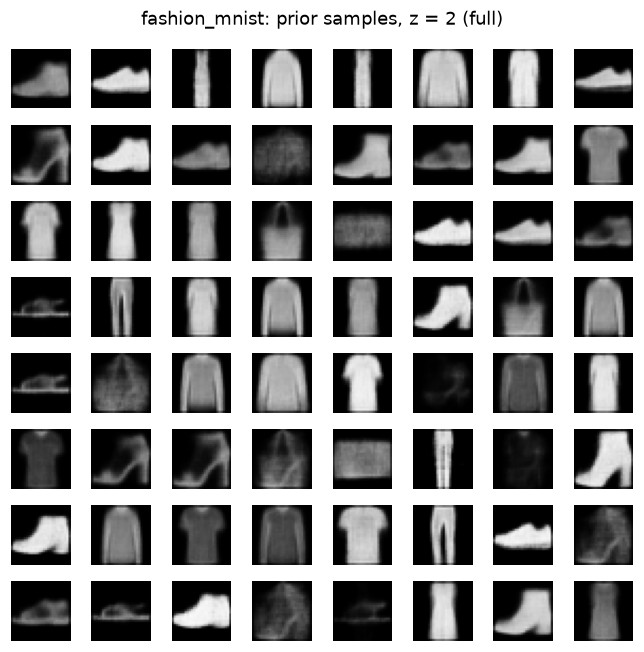

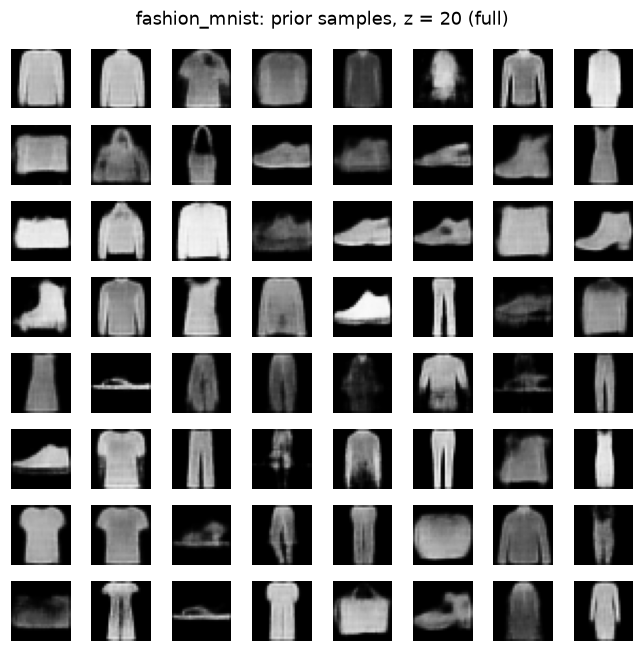

In [20]:
for (name, dim), run in runs.items():
    model, _ = load_vae(run["checkpoint"], device)
    generator = torch.Generator().manual_seed(SEED + 10)
    z = torch.randn(64, dim, generator=generator).to(device)
    with torch.inference_mode():
        images = model.decode(z).cpu()
    fig, axes = plt.subplots(8, 8, figsize=(6, 6))
    for ax, image in zip(axes.flat, images):
        ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(f"{name}: prior samples, z = {dim} ({MODE})")
    fig.tight_layout()
    show_figure(fig, f"{name}_z{dim}_prior_samples.png")
    del model


## 10. Latent interpolation

We encode two validation images, then interpolate between their posterior means:

$$z(a) = (1-a)\mu_1 + a\mu_2, \qquad a\in[0,1].$$

Decoding these points shows how the representation changes between the examples. The endpoints are reconstructions, and the intermediate points are not guaranteed to lie in a region well supported by training data. Interpolation is a qualitative probe, not a generation-quality metric.


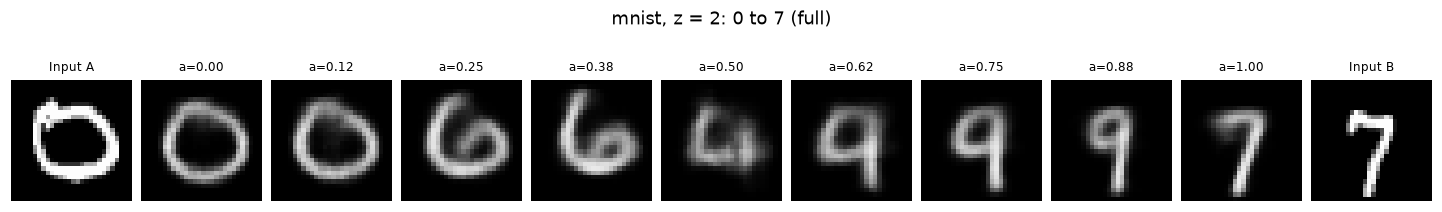

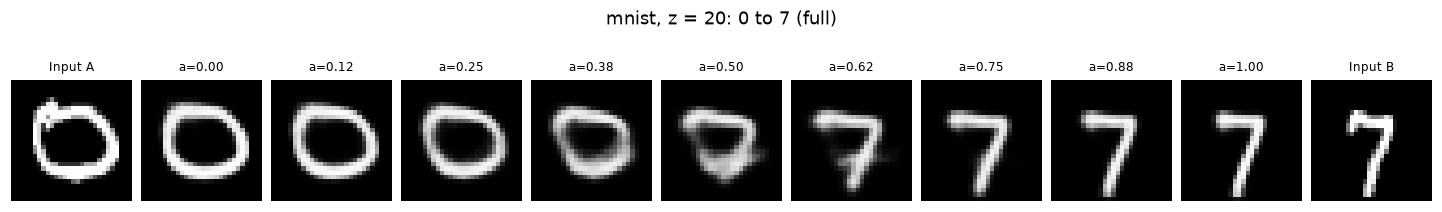

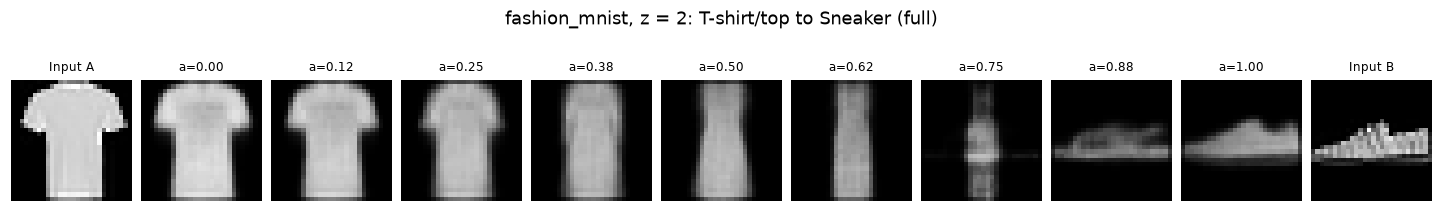

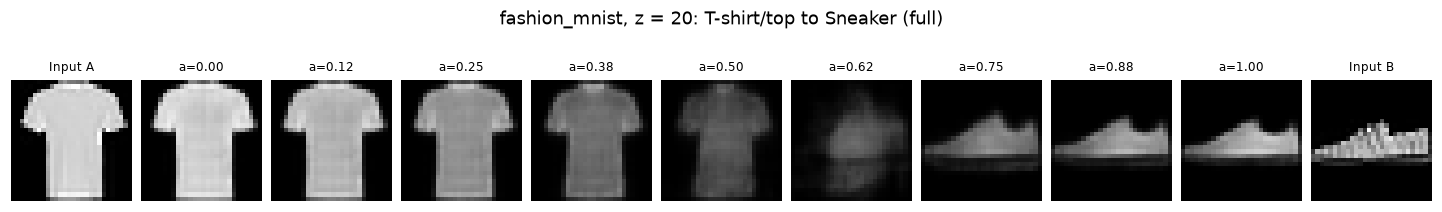

In [21]:
PAIR = (0, 7)  # Class indices; the same validation examples as above.
for (name, dim), run in runs.items():
    model, _ = load_vae(run["checkpoint"], device)
    endpoints = examples[name][list(PAIR)].to(device)
    with torch.inference_mode():
        mu, _ = model.encode(endpoints)
        weights = torch.linspace(0, 1, 9, device=device).unsqueeze(1)
        z = (1 - weights) * mu[0] + weights * mu[1]
        images = model.decode(z).cpu()
    fig, axes = plt.subplots(1, 11, figsize=(13, 2.2), constrained_layout=True)
    all_images = torch.cat([endpoints[:1].cpu(), images, endpoints[1:].cpu()])
    titles = ["Input A"] + [f"a={a:.2f}" for a in np.linspace(0, 1, 9)] + ["Input B"]
    for ax, image, title in zip(axes, all_images, titles):
        ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{name}, z = {dim}: {data[name]['classes'][PAIR[0]]} to {data[name]['classes'][PAIR[1]]} ({MODE})")
    show_figure(fig, f"{name}_z{dim}_interpolation.png")
    del model


## 11. The 2D latent space

For the 2D models, we plot posterior means from up to 2,000 validation images. Using means removes the sampling noise from the scatter plot. Colors indicate the known classes, although the model was trained without labels. Visual separation is not a clustering score; quantitative clustering will be handled in its own notebook.

We also decode a regular grid from -3 to 3 along each latent coordinate. This shows what the decoder produces across the plane. The grid is not a random sample from the Gaussian prior; the corner regions have relatively low prior density.


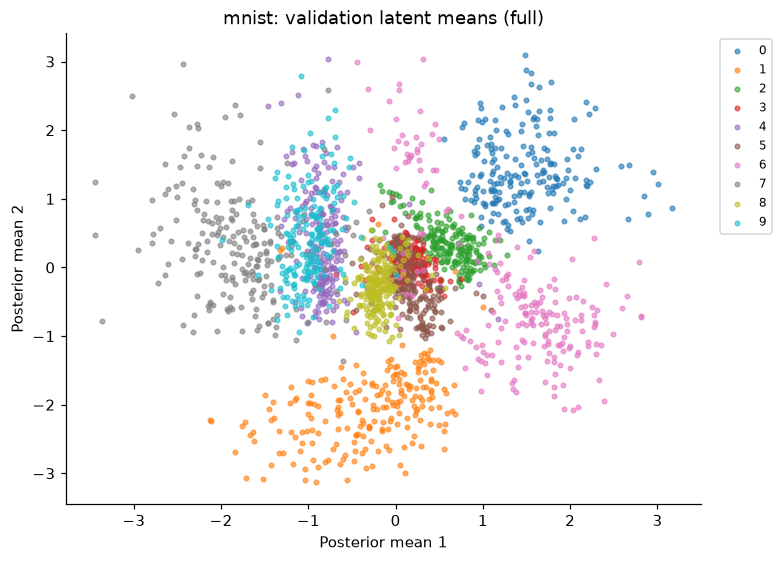

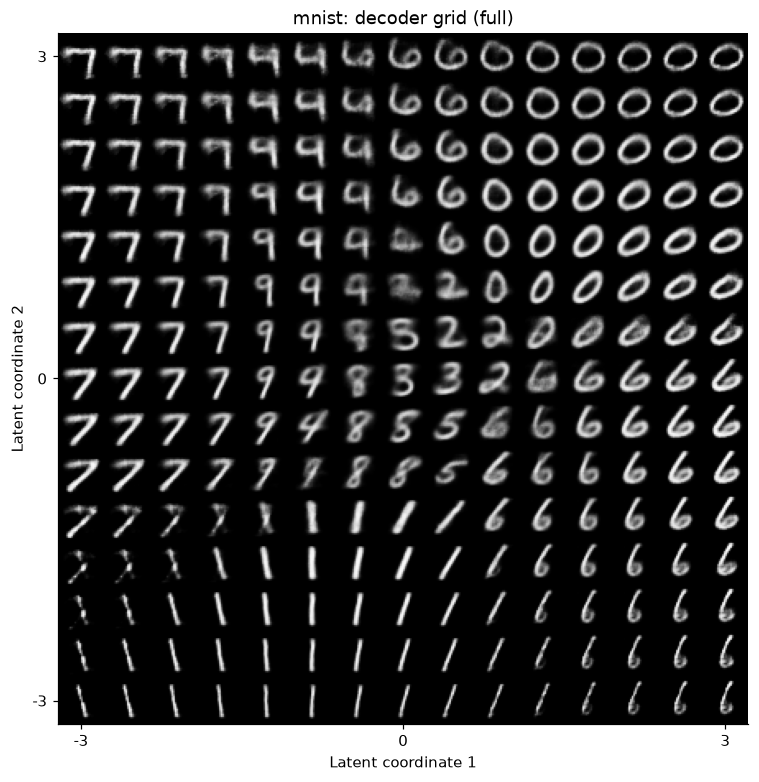

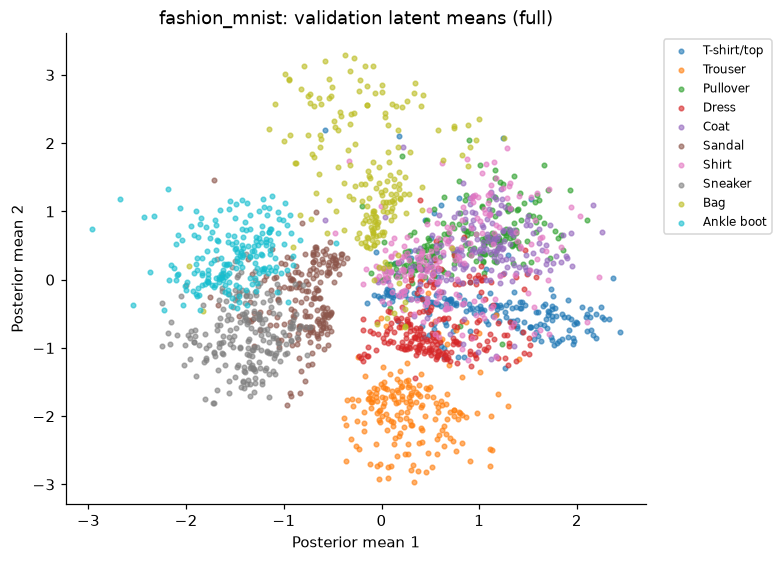

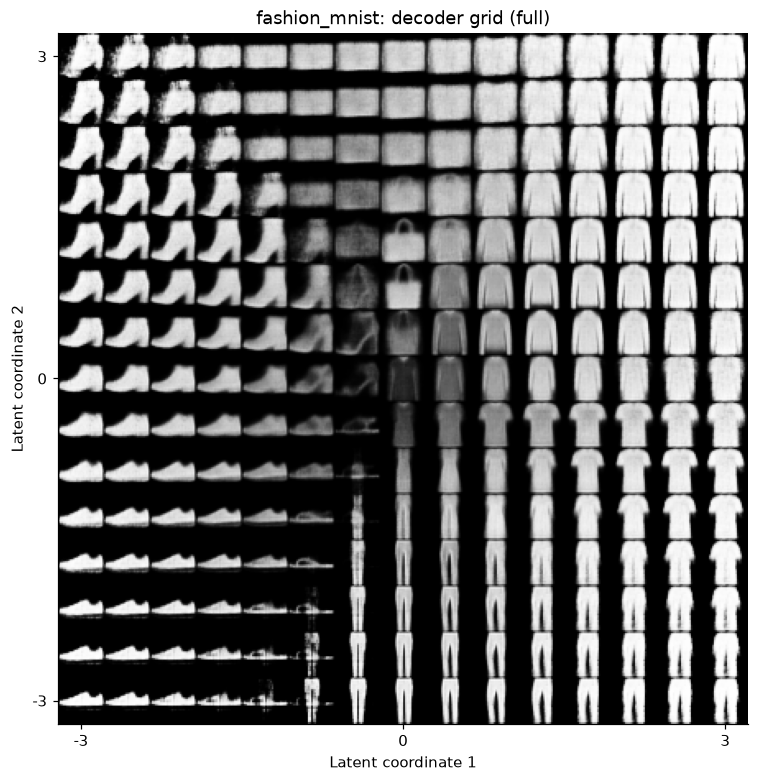

In [22]:
if 2 in LATENT_DIMS:
    for name in DATASET_NAMES:
        model, _ = load_vae(runs[(name, 2)]["checkpoint"], device)
        entry = data[name]
        rng = np.random.default_rng(SEED)
        indices = rng.choice(entry["val_idx"], size=min(2000, len(entry["val_idx"])), replace=False)
        loader = DataLoader(Subset(entry["dataset"], indices.tolist()), batch_size=BATCH_SIZE, shuffle=False)
        means, labels = [], []
        with torch.inference_mode():
            for x, y in loader:
                mu, _ = model.encode(x.to(device))
                means.append(mu.cpu())
                labels.append(y)
        means = torch.cat(means).numpy()
        labels = torch.cat(labels).numpy()
        fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
        for label in range(10):
            mask = labels == label
            ax.scatter(means[mask, 0], means[mask, 1], s=9, alpha=0.6,
                       color=plt.get_cmap("tab10")(label), label=entry["classes"][label])
        ax.set(xlabel="Posterior mean 1", ylabel="Posterior mean 2",
               title=f"{name}: validation latent means ({MODE})")
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
        show_figure(fig, f"{name}_z2_latent_means.png")

        grid_size = 15
        coordinates = torch.linspace(-3, 3, grid_size)
        z = torch.tensor([[x.item(), y.item()] for y in coordinates.flip(0) for x in coordinates], device=device)
        with torch.inference_mode():
            images = model.decode(z).cpu()[:, 0]
        canvas = images.reshape(grid_size, grid_size, 28, 28).permute(0, 2, 1, 3).reshape(grid_size * 28, grid_size * 28)
        fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
        ax.imshow(canvas.numpy(), cmap="gray", vmin=0, vmax=1)
        centers = np.array([0, grid_size // 2, grid_size - 1]) * 28 + 13.5
        ax.set_xticks(centers, ["-3", "0", "3"])
        ax.set_yticks(centers, ["3", "0", "-3"])
        ax.set(xlabel="Latent coordinate 1", ylabel="Latent coordinate 2",
               title=f"{name}: decoder grid ({MODE})")
        show_figure(fig, f"{name}_z2_decoder_grid.png")
        del model


## 12. Results and discussion

Both models improved during training, although the models with 20 latent dimensions reached lower validation losses.
For MNIST, increasing the latent dimension from 2 to 20 reduced the validation loss from 144.49 to 97.07. The difference was smaller for Fashion-MNIST, where the loss decreased from 257.45 to 235.60.
This suggests that a larger latent space helps the model reconstruct the input images more accurately. However, the 2D representation is still useful because it allows us to visualize how the images are distributed in the latent space.
